In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# --- Definicja Kolorów IDEAS NCBR ---
IDEAS_TEAL = "#004b50"
IDEAS_MINT = "#2a8a8f"
IDEAS_LIGHT = "#6ab2b5"
IDEAS_CHARCOAL = "#1a1d20"
IDEAS_CORAL = "#e06d53"  # Akcent do wyróżnień (np. progi, stan docelowy)

# --- Paleta Kategorialna (np. do klastrów / typów komórek) ---
IDEAS_PALETTE = [IDEAS_TEAL, IDEAS_MINT, IDEAS_LIGHT, "#a8dadc", IDEAS_CORAL]
sns.set_palette(IDEAS_PALETTE)

# --- Ciągła Mapa Kolorów (np. do ekspresji genów / macierzy scRNA-seq) ---
cmap_ideas_seq = LinearSegmentedColormap.from_list(
    "ideas_seq", ["#f0f5f5", IDEAS_LIGHT, IDEAS_TEAL, "#002a2d"]
)

# --- Globalne Ustawienia Stylu ---
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "figure.facecolor": "none",       # Przezroczyste tło (idealne do wklejenia na poster)
    "axes.facecolor": "none",
    "axes.edgecolor": IDEAS_CHARCOAL,
    "axes.linewidth": 1.2,
    "axes.labelcolor": IDEAS_CHARCOAL,
    "axes.labelsize": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "xtick.color": IDEAS_CHARCOAL,
    "ytick.color": IDEAS_CHARCOAL,
    "grid.color": "#d0dadb",
    "grid.linestyle": "--",
    "grid.linewidth": 0.6,
    "legend.frameon": True,
    "legend.facecolor": "#ffffff",
    "legend.edgecolor": "#d0dadb"
})

## Gene expression heatmap

In [14]:
import numpy as np
import scanpy as sc
from scipy import sparse

N_HVG = 100
N_CELLS = 100
rng = np.random.default_rng(0)

In [15]:
# surowe counts z "0. Data Preprocessing.ipynb"
adata = sc.read_h5ad("merged_dataset.h5ad")

In [4]:
# HVG tą samą metodą co w notebooku 0 (seurat_v3 działa na surowych counts), liczone na wszystkich komórkach
sc.pp.highly_variable_genes(adata, flavor="seurat_v3", n_top_genes=N_HVG, batch_key="batch")

# losowa próbka komórek, potem CP10k + log1p (jak w pierwszej wersji, daje czytelny kontrast)
sub = adata[rng.choice(adata.n_obs, N_CELLS, replace=False)].copy()
sc.pp.normalize_total(sub, target_sum=1e4)
sc.pp.log1p(sub)

# tylko HVG, w losowej kolejności (bez sortowania, brak gradientu)
hvg = np.flatnonzero(sub.var["highly_variable"].values)
X = sub.X[:, rng.permutation(hvg)]
X = X.toarray() if sparse.issparse(X) else np.asarray(X)

cmap_scrna = cmap_ideas_seq

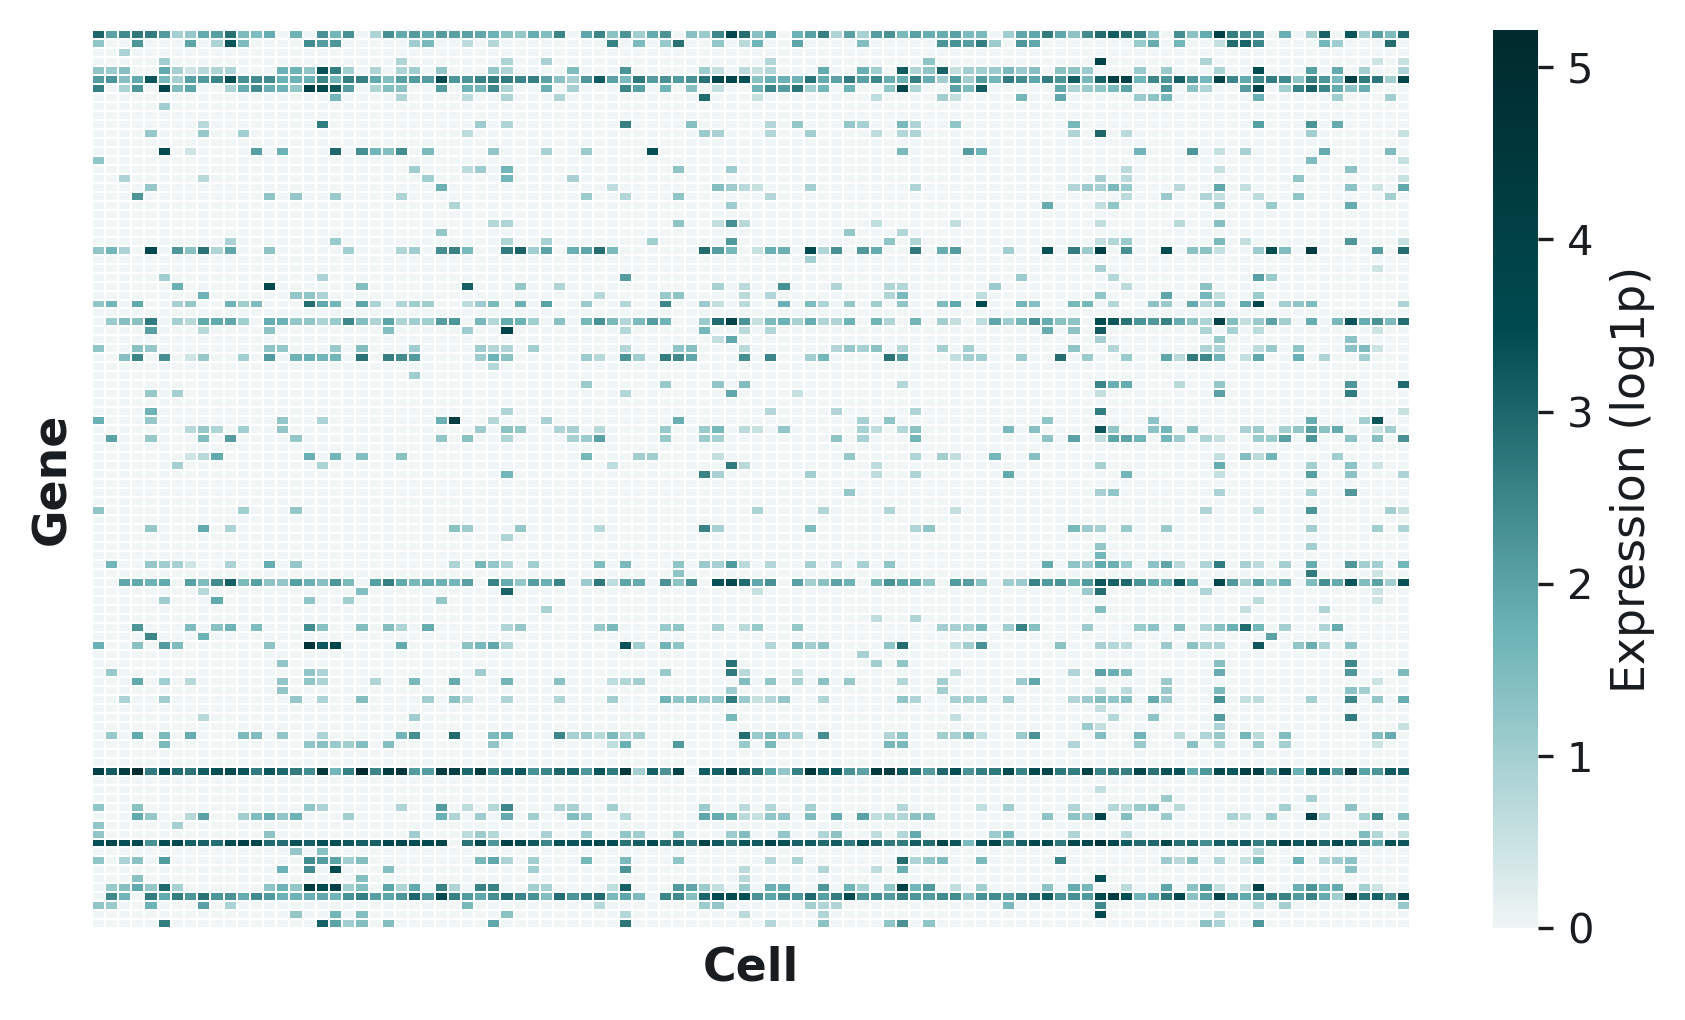

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.5), dpi=300)

# geny na osi Y, komórki na osi X
sns.heatmap(
    X.T,
    cmap=cmap_scrna,
    ax=ax,
    cbar_kws={'label': 'Expression (log1p)'},
    xticklabels=False,
    yticklabels=False,
    linewidths=0.1,
    linecolor='#ffffff',
    rasterized=True,
)

ax.set_xlabel(r"Cell", fontweight='bold')
ax.set_ylabel(r"Gene", fontweight='bold')

plt.tight_layout()
plt.savefig("figures/scrna_heatmap_ideas_style.pdf", bbox_inches='tight', transparent=True)
plt.savefig("figures/scrna_heatmap_ideas_style.svg", bbox_inches='tight', facecolor="white")
plt.savefig("figures/scrna_heatmap_ideas_style.png", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## HVG plot

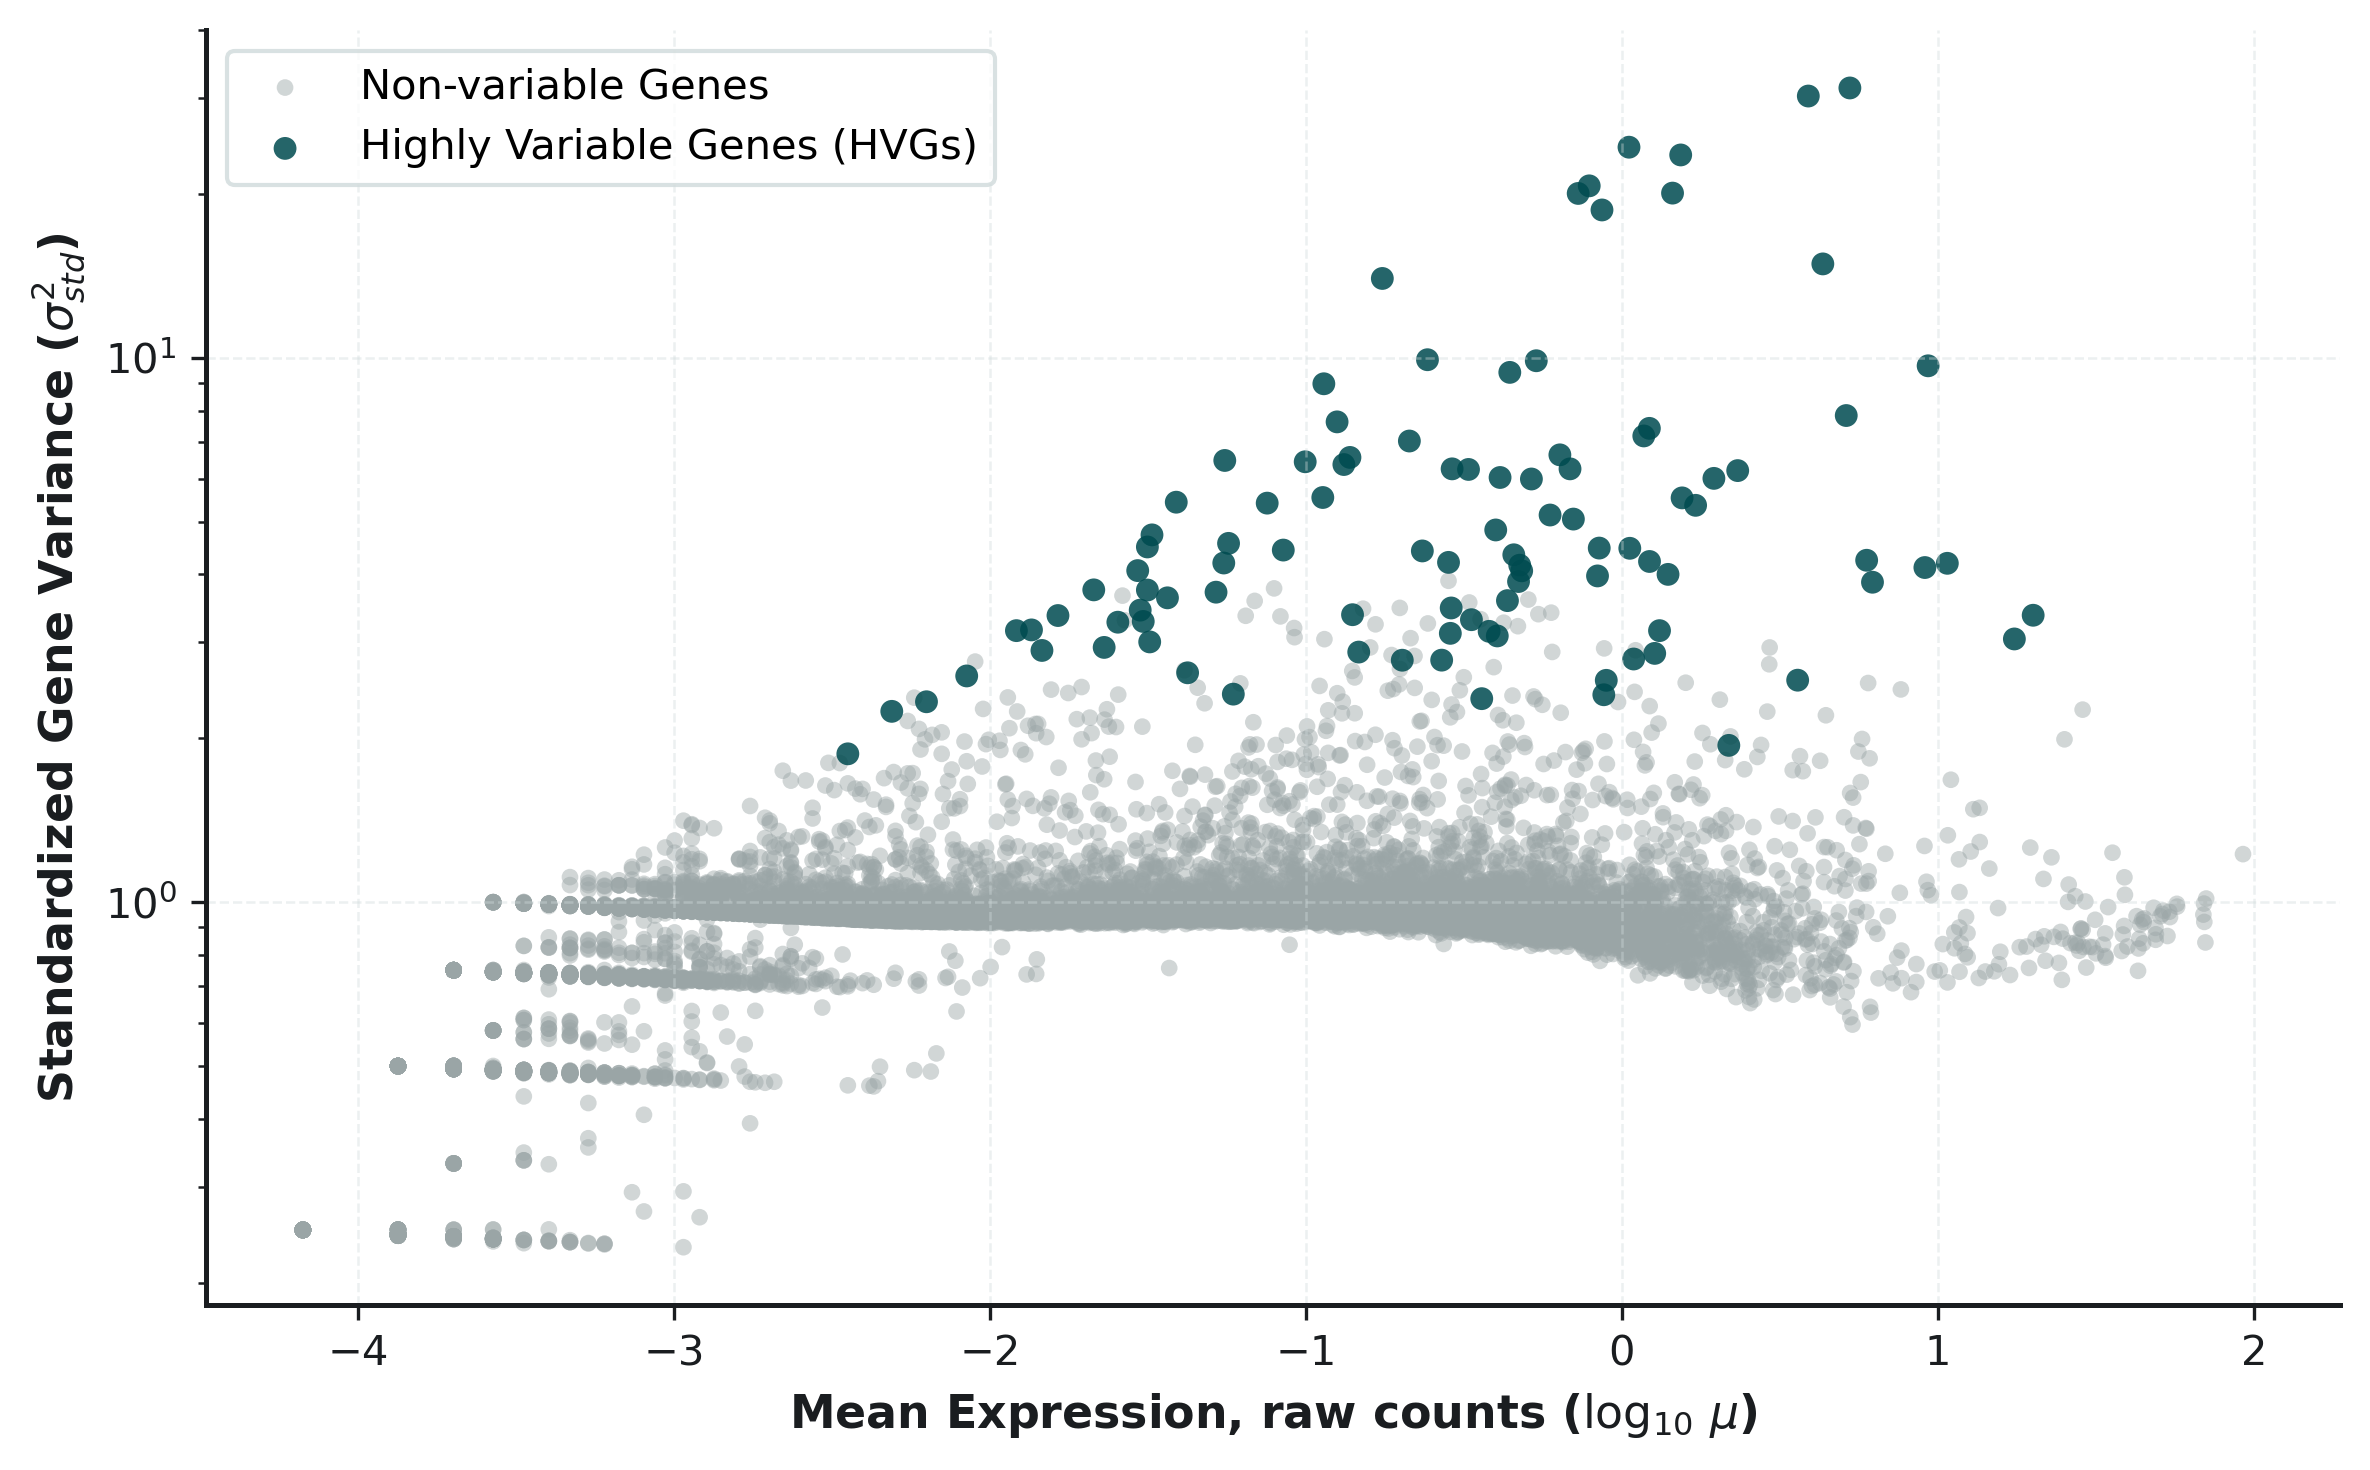

In [8]:
# --- DANE Z adata.var (policzone w komórce z heatmapą przez sc.pp.highly_variable_genes, seurat_v3) ---
# means / variances_norm to średnia i znormalizowana wariancja surowych counts, uśrednione po batchach
df_hvg = adata.var.loc[adata.var["means"] > 0, ["means", "variances_norm", "highly_variable"]].copy()
df_hvg["log_mean"] = np.log10(df_hvg["means"])

# Wyróżnione geny: top 6 HVG wg znormalizowanej wariancji
top_annotated = df_hvg[df_hvg["highly_variable"]].nlargest(6, "variances_norm")

# --- GENEROWANIE WYKRESU ---
fig, ax = plt.subplots(figsize=(8, 5.0), dpi=300)

# rasterized=True: ~28 tys. punktów trafia do SVG/PDF jako jeden obraz (osie i tekst zostają wektorowe)
# Punkty tła (niezmienne geny)
sns.scatterplot(data=df_hvg[~df_hvg['highly_variable']], x='log_mean', y='variances_norm',
                color="#9aa5a6", alpha=0.45, s=16, edgecolor='none', ax=ax, label='Non-variable Genes',
                rasterized=True)

# Wyselekcjonowane HVGs
sns.scatterplot(data=df_hvg[df_hvg['highly_variable']], x='log_mean', y='variances_norm',
                color=IDEAS_TEAL, alpha=0.85, s=30, edgecolor='none', ax=ax, label='Highly Variable Genes (HVGs)',
                rasterized=True)

# Annotacje najważniejszych genów
'''for gene, row in top_annotated.iterrows():
    ax.scatter(row['log_mean'], row['variances_norm'], color=IDEAS_CORAL, s=40, zorder=5)
    ax.annotate(gene, (row['log_mean'], row['variances_norm']),
                xytext=(row['log_mean'] + 0.15, row['variances_norm'] * 1.05), fontsize=9,
                fontweight='bold', color=IDEAS_CHARCOAL,
                arrowprops=dict(arrowstyle="->", color=IDEAS_TEAL, lw=0.9))'''

ax.set_yscale('log')
ax.set_xlabel(r"Mean Expression, raw counts ($\log_{10}\,\mu$)", fontweight='bold')
ax.set_ylabel(r"Standardized Gene Variance ($\sigma_{std}^2$)", fontweight='bold')

sns.despine(ax=ax)
ax.grid(True, linestyle='--', alpha=0.4)
#ax.legend(loc='lower right', frameon=True, facecolor='#ffffff', edgecolor='#e5e7eb', fontsize=9)

plt.tight_layout()
plt.savefig("figures/hvg_selection_ideas.pdf", bbox_inches='tight', transparent=True)
plt.savefig("figures/hvg_selection_ideas.svg", dpi=300, bbox_inches='tight', facecolor="white")  # dpi = rozdzielczość warstwy rastrowej
plt.savefig("figures/hvg_selection_ideas.png", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## Leiden Clusterization

In [4]:
IDEAS_9_PALETTE = [
    "#004b50",  # C1: Ciemny cyjan (IDEAS Primary)
    "#007a82",  # C2: Głęboki morski
    "#2a8a8f",  # C3: Mięta
    "#52b2b7",  # C4: Jasny cyjan
    "#1e3d59",  # C5: Granat łupkowy
    "#e06d53",  # C6: Miedziany koral (akcent)
    "#d99b26",  # C7: Złoty ochra (akcent)
    "#6b7c96",  # C8: Szary błękit
    "#9b6b9e"   # C9: Zgaszony fiolet
]

In [5]:
# --- 500 HVG (seurat_v3 na surowych counts, jak w notebooku 0) ---
# inplace=False: nie nadpisujemy adata.var, z którego korzysta sekcja HVG plot (tam N_HVG = 100)
N_HVG_LEIDEN = 500
N_PCS = 100
hvg_df = sc.pp.highly_variable_genes(
    adata, flavor="seurat_v3", n_top_genes=N_HVG_LEIDEN, batch_key="batch", inplace=False
)
adata_leiden = adata[:, hvg_df["highly_variable"].values].copy()
adata_leiden.X = adata_leiden.X.astype(np.float32)

# normalizacja po wyborze HVG (CP10k + log1p), tak jak w pipeline'ie z notebooka 0 (dataset_hvgs.csv)
sc.pp.normalize_total(adata_leiden, target_sum=1e4)
sc.pp.log1p(adata_leiden)

# PCA (100 PC) -> kNN -> UMAP -> Leiden; parametry jak w "1. Clusterization (legacy).ipynb"
sc.pp.pca(adata_leiden, n_comps=N_PCS)
sc.pp.neighbors(adata_leiden, n_neighbors=15, n_pcs=N_PCS)
sc.tl.umap(adata_leiden)
sc.tl.leiden(adata_leiden, resolution=1.0, flavor="igraph", n_iterations=2)

clusters = adata_leiden.obs["leiden"].cat.categories
print(f"{len(clusters)} klastrów Leiden")
assert len(clusters) <= len(IDEAS_9_PALETTE), "więcej klastrów niż kolorów w IDEAS_9_PALETTE"
adata_leiden.obs["leiden"].value_counts(normalize=True).mul(100).round(1)

9 klastrów Leiden


leiden
8    24.3
0    21.6
1    16.1
5    15.9
3    10.1
2     4.6
7     3.6
4     2.8
6     0.9
Name: proportion, dtype: float64

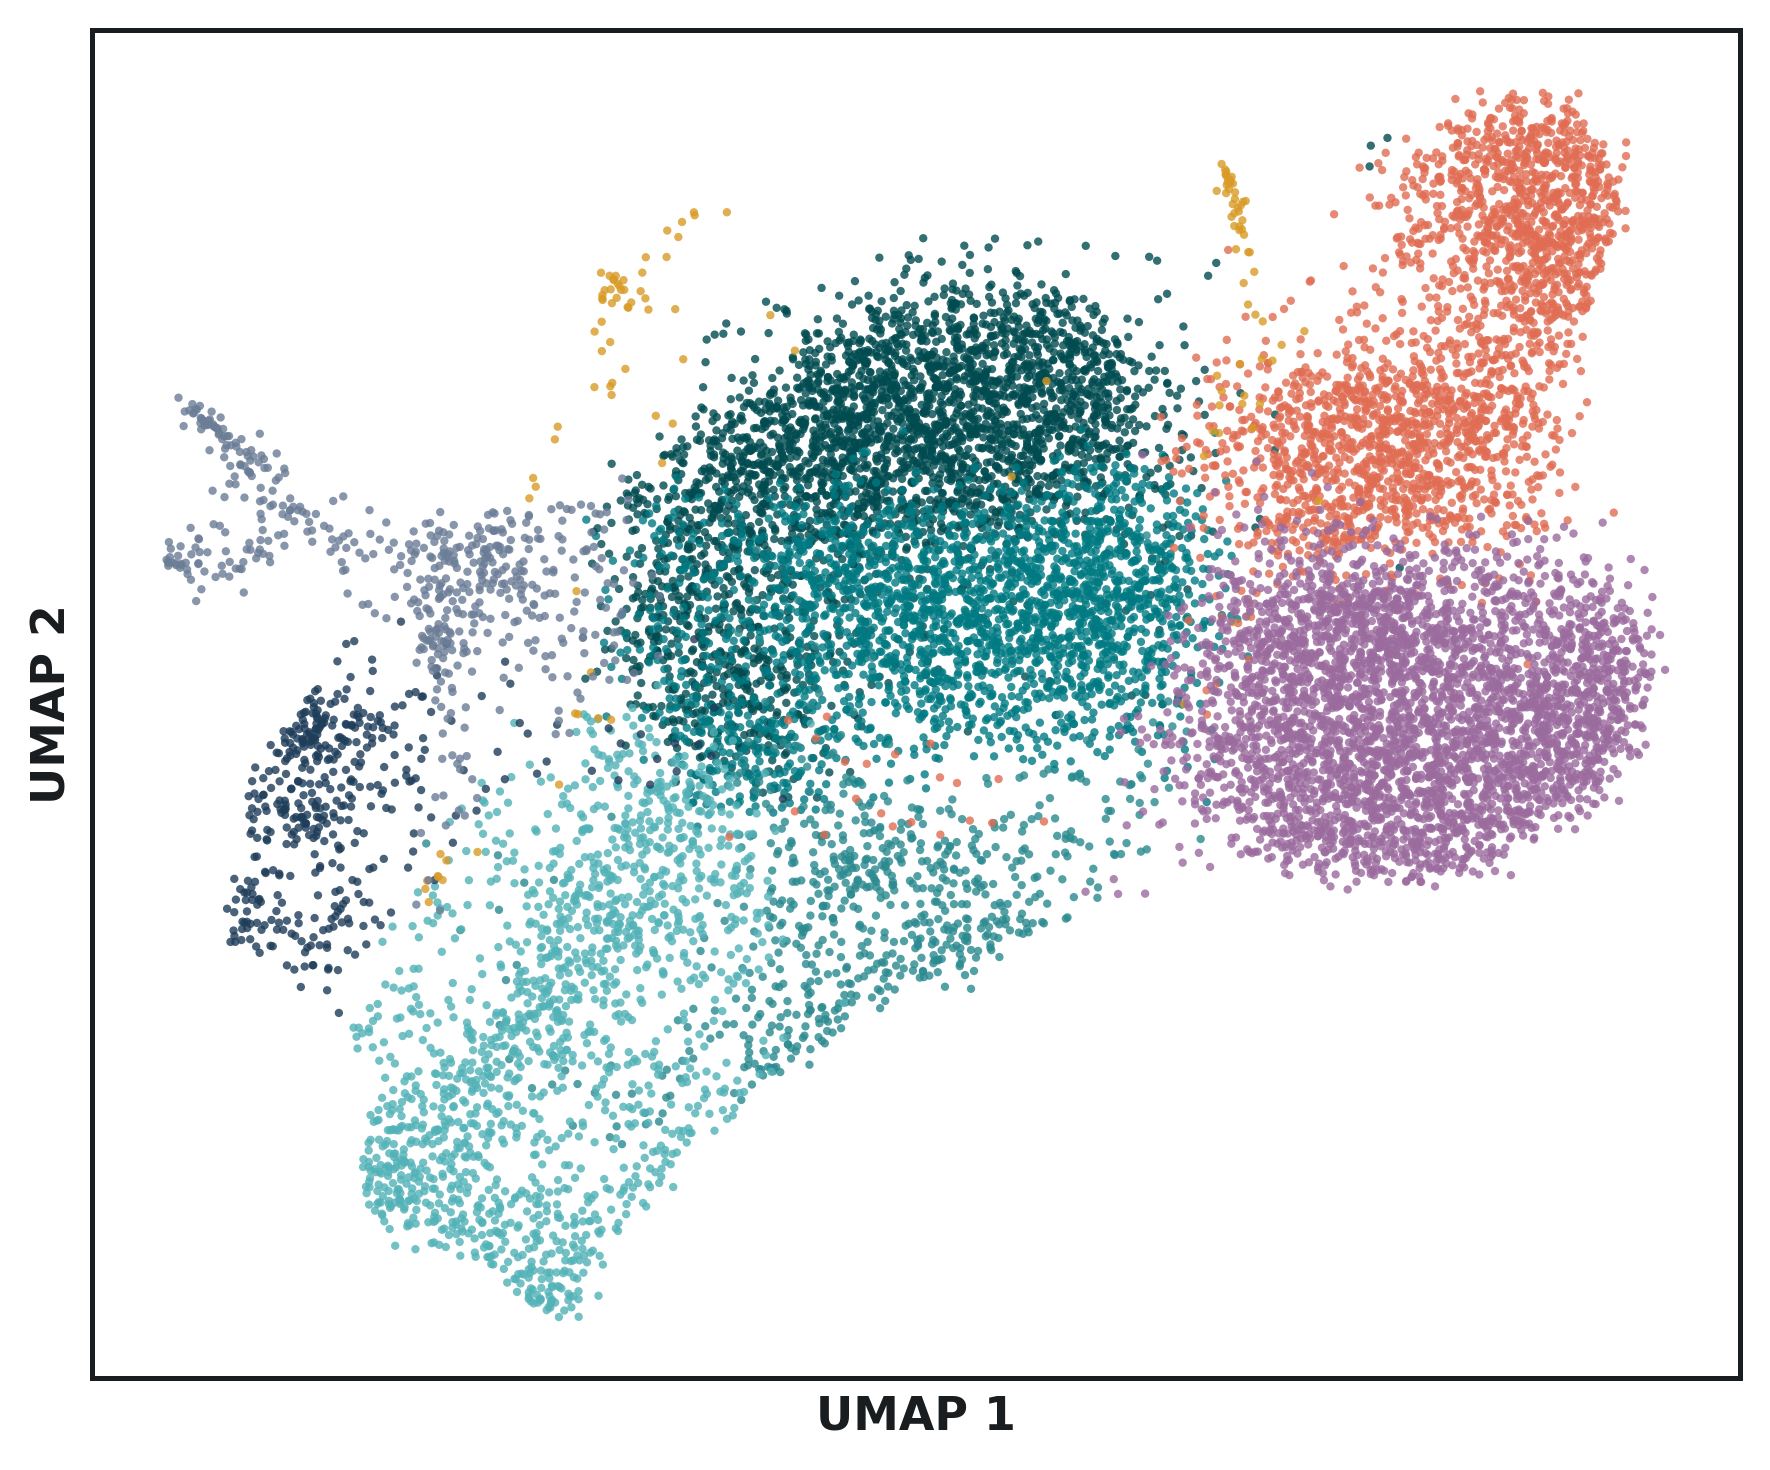

In [9]:
umap_xy = adata_leiden.obsm["X_umap"]
labels = adata_leiden.obs["leiden"].values

fig, ax = plt.subplots(figsize=(6, 5), dpi=300)

# rasterized=True: ~15 tys. punktów jako jeden obraz w SVG/PDF (osie i legenda zostają wektorowe)
for i, cl in enumerate(clusters):
    m = labels == cl
    ax.scatter(umap_xy[m, 0], umap_xy[m, 1], s=4, alpha=0.8, edgecolor='none',
               color=IDEAS_9_PALETTE[i], label=f"C{i + 1}", rasterized=True)

#ax.set_axis_off()
'''leg = ax.legend(title="Leiden cluster", loc='center left', bbox_to_anchor=(1.0, 0.5),
                markerscale=3, fontsize=9, title_fontsize=10, ncol=1)'''
ax.set_xlabel(r"UMAP 1", fontweight='bold')
ax.set_ylabel(r"UMAP 2", fontweight='bold')
ax.set_xticks([])
ax.set_yticks([])


plt.tight_layout()
plt.savefig("figures/umap_leiden_ideas.pdf", bbox_inches='tight', transparent=True)
plt.savefig("figures/umap_leiden_ideas.svg", dpi=300, bbox_inches='tight', facecolor="white")
plt.savefig("figures/umap_leiden_ideas.png", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## Pseudotime Trajectory & RNA Velocity

In [16]:
import pandas as pd

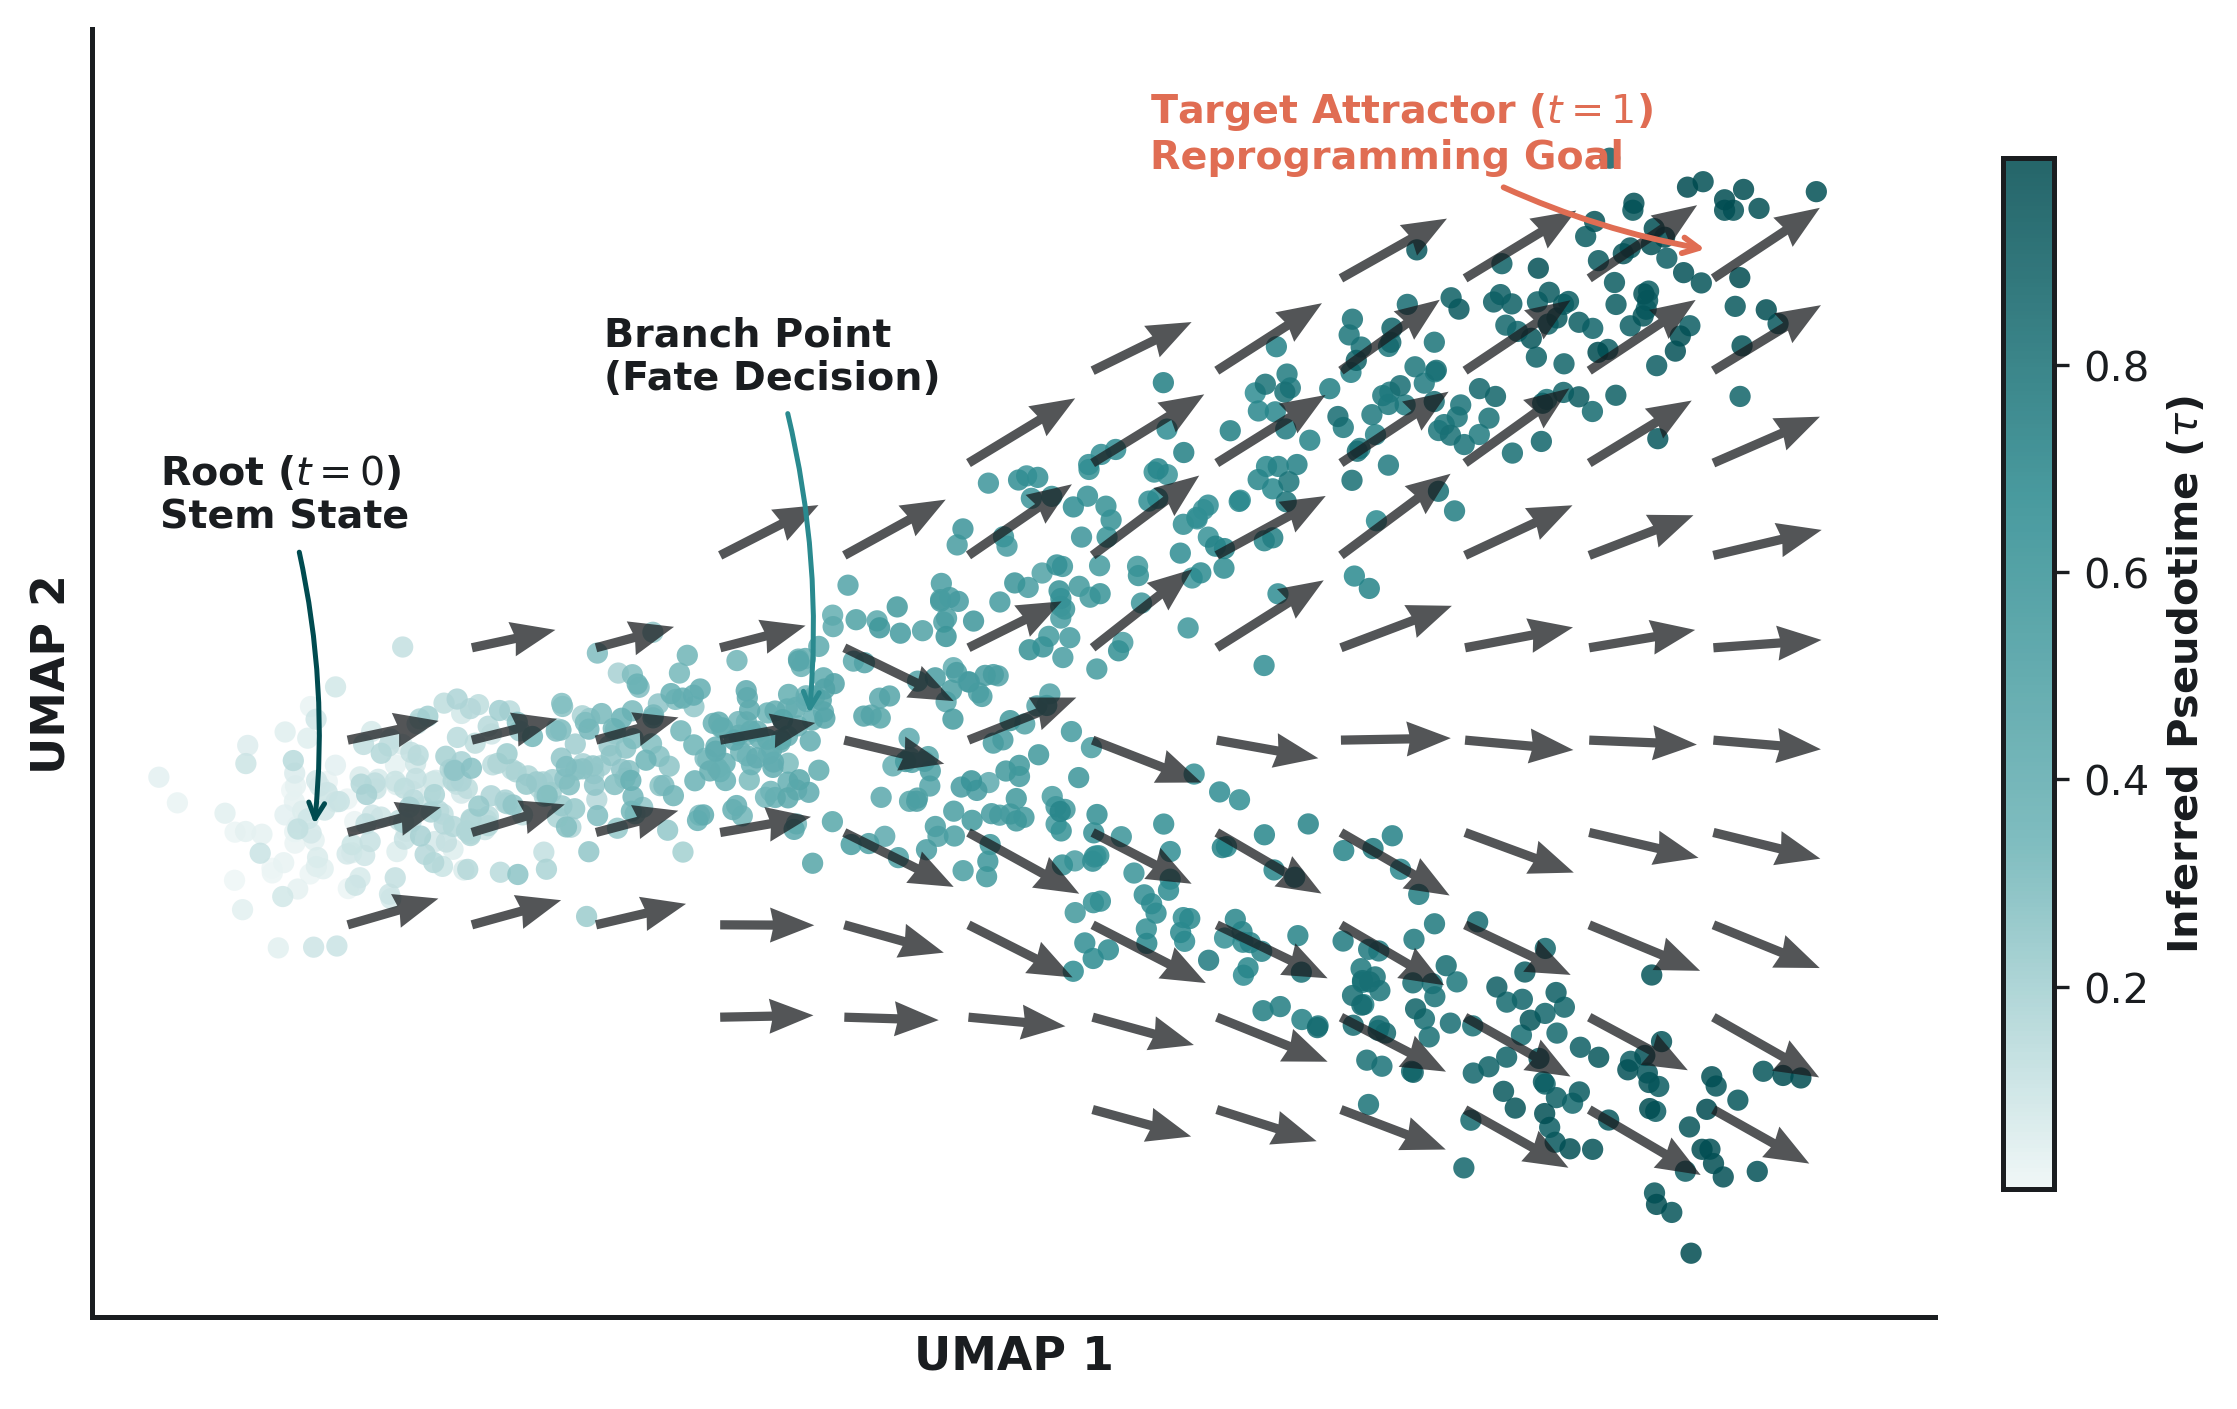

In [17]:
ACCENT_CORAL = IDEAS_CORAL  # alias używany w adnotacjach poniżej

# --- GENEROWANIE SYNTEZY DANYCH TRAJEKTORII I PRĘDKOŚCI ---
np.random.seed(42)
n_points = 800
t = np.sort(np.random.uniform(0, 1, n_points))
branch = np.random.choice([0, 1], size=n_points, p=[0.55, 0.45])

umap1, umap2, vx, vy = [], [], [], []
for ti, b in zip(t, branch):
    if ti < 0.4:  # Ppień (Stem)
        x = ti * 8 + np.random.normal(0, 0.35)
        y = 2 + ti * 2 + np.random.normal(0, 0.35)
        dx, dy = 1.2 + np.random.normal(0, 0.1), 0.3 + np.random.normal(0, 0.1)
    else:  # Rozgałęzienie (Branching)
        if b == 0:  # Linia docelowa (Target Lineage)
            x = 3.2 + (ti - 0.4) * 9 + np.random.normal(0, 0.4)
            y = 2.8 + (ti - 0.4) * 6 + np.random.normal(0, 0.4)
            dx, dy = 1.5 + np.random.normal(0, 0.1), 1.0 + np.random.normal(0, 0.1)
        else:  # Linia alternatywna
            x = 3.2 + (ti - 0.4) * 9 + np.random.normal(0, 0.4)
            y = 2.8 - (ti - 0.4) * 5 + np.random.normal(0, 0.4)
            dx, dy = 1.5 + np.random.normal(0, 0.1), -0.8 + np.random.normal(0, 0.1)
    umap1.append(x); umap2.append(y); vx.append(dx); vy.append(dy)

df_traj = pd.DataFrame({'UMAP_1': umap1, 'UMAP_2': umap2, 'Pseudotime': t, 'Vx': vx, 'Vy': vy})

# Siatka dla wektorów prędkości (Quiver Grid)
grid_x, grid_y = np.meshgrid(np.linspace(0.5, 8.5, 12), np.linspace(0, 6, 10))
from scipy.interpolate import griddata
grid_vx = griddata((df_traj['UMAP_1'], df_traj['UMAP_2']), df_traj['Vx'], (grid_x, grid_y), method='linear')
grid_vy = griddata((df_traj['UMAP_1'], df_traj['UMAP_2']), df_traj['Vy'], (grid_x, grid_y), method='linear')
mask = ~np.isnan(grid_vx)

# --- WYKRES ---
cmap_pseudotime = LinearSegmentedColormap.from_list("pt_ideas", ["#eef6f6", IDEAS_LIGHT, IDEAS_MINT, IDEAS_TEAL])

fig, ax = plt.subplots(figsize=(8, 4.8), dpi=300)

# 1. Punkty komórek pokolorowane pseudotempem (nie nazywamy tego `sc` - to nadpisywałoby scanpy)
pts = ax.scatter(df_traj['UMAP_1'], df_traj['UMAP_2'], c=df_traj['Pseudotime'], cmap=cmap_pseudotime, s=26, alpha=0.85, edgecolor='none')

# 2. Wektory dynamiki (RNA Velocity)
ax.quiver(grid_x[mask], grid_y[mask], grid_vx[mask], grid_vy[mask], color=IDEAS_CHARCOAL, alpha=0.75, scale=26, width=0.005, headwidth=3.8, headlength=4.8)

# 3. Adnotacje kamieni milowych
ax.annotate('Root ($t=0$)\nStem State', xy=(0.3, 2.0), xytext=(-0.6, 4.2), fontsize=9.5, fontweight='bold', color=IDEAS_CHARCOAL, arrowprops=dict(arrowstyle="->", color=IDEAS_TEAL, lw=1.2, connectionstyle="arc3,rad=-0.1"))
ax.annotate('Branch Point\n(Fate Decision)', xy=(3.2, 2.8), xytext=(2.0, 5.2), fontsize=9.5, fontweight='bold', color=IDEAS_CHARCOAL, arrowprops=dict(arrowstyle="->", color=IDEAS_MINT, lw=1.2, connectionstyle="arc3,rad=-0.1"))
ax.annotate('Target Attractor ($t=1$)\nReprogramming Goal', xy=(8.5, 6.2), xytext=(5.2, 6.8), fontsize=9.5, fontweight='bold', color=ACCENT_CORAL, arrowprops=dict(arrowstyle="->", color=ACCENT_CORAL, lw=1.4, connectionstyle="arc3,rad=0.1"))

cbar = plt.colorbar(pts, ax=ax, shrink=0.8, pad=0.03)
cbar.set_label(r'Inferred Pseudotime ($\tau$)', fontweight='bold', fontsize=10)

ax.set_ylim(-1.5, 7.8); ax.set_xlim(-1.0, 9.8)
ax.set_xlabel("UMAP 1", fontweight='bold'); ax.set_ylabel("UMAP 2", fontweight='bold')
ax.set_xticks([]); ax.set_yticks([])

sns.despine(ax=ax)
plt.tight_layout()
plt.savefig("figures/trajectory_velocity_ideas.pdf", bbox_inches='tight', transparent=True)
plt.savefig("figures/trajectory_velocity_ideas.svg", dpi=300, bbox_inches='tight', facecolor="white")
plt.savefig("figures/trajectory_velocity_ideas.png", dpi=300, bbox_inches='tight', transparent=True)
plt.show()